In [1]:
import numpy as np
import pandas as pd

# Data Preprocessing

- Lesion assessment (label-)processing
- Processing of refined labels
    - Binary classification: Healthy VS. Cancer
    - Binary classification: Cancer VS. (Healthy, Benign, Dysplasia)
    - MC classification: Healthy, Benign, Mild dysplasia, Moderate Dysplasia, Severe Dysplasia, Cancer
- Loading of MATLAB data file
- Export of samples to `data`

## Lesion assessment (label-)processing

In [4]:
lesion_path = "source/Labeled_Data_lesion_info-17-Sep-2025.csv"

In [5]:
lesion_info = pd.read_csv(lesion_path)

LesionCase = lesion_info["Case"]
LesionLoc = lesion_info[" LesionLoc"]
LesionAssessment = lesion_info[" LesionAssessment"]
Encoding = lesion_info[" Encoder"]


def normalize_str(text):
    return text.strip().lower()


# used for export
lesion_loc = [normalize_str(loc) for loc in LesionLoc]
lesion_assessment = [normalize_str(cat) for cat in LesionAssessment]
lesion_encoding = [str(enc) for enc in Encoding]

In [6]:
# Create the normalized string descriptions
lesion_info["lesion_loc"] = lesion_loc
lesion_info["lesion_assessment"] = lesion_assessment

**Available data**

| String | Count | Label                            |
|--------|-------|----------------------------------|
| 0      | 99    | healthy                          |
| 1      | 93    | carcinoma + adenocarcinoma       |
| 2      | 19    | mild/moderate dysplasia          |
| 3      | 18    | high grade dysplasia/cis         |
| 4      | 13    | benign                           |
| 5      | 2     | leukoplakia                      |

## Processing of refined labels

In [7]:
from typing import Union


def assessment_wrapping(lesion_assessment: Union[list, np.ndarray], mapping: dict):
    """
    Applies a mapping to a list or array of lesion assessments and returns the new labeled array.

    Parameters:
        lesion_assessment (list or np.ndarray): List or array of original lesion assessment labels.
        mapping (dict): Dictionary mapping original labels to new labels (e.g., 'Cancer' -> 1).

    Returns:
        np.ndarray: A new NumPy array with the mapped labels.
    """
    # create a copy of e.g., lesion assessment
    lesion_assessment = np.array(lesion_assessment)  # ensure it's a NumPy array
    labeled = np.array([mapping[label] for label in lesion_assessment])
    return labeled


def find_all_indices(array, target_values, split=False):
    """
    Returns the indices of all occurrences of specified target values in a list.

    Parameters:
        array (list): The list to search through.
        target_values (str or list): A single string or a list of strings to search for.
        split (bool, optional): If True, returns a dictionary mapping each target value
                                to a list of its indices. If False (default), returns a
                                flat list of all matching indices.

    Returns:
        list or dict:
            - If split is False: a list of indices where any target value occurs in the array.
            - If split is True: a dictionary where each key is a target value and the value
              is a list of indices where that value appears in the array.

    Example:
        >>> array = ['a', 'b', 'c', 'a', 'b']
        >>> find_all_indices(array, 'a')
        [0, 3]
        >>> find_all_indices(array, ['a', 'b'])
        [0, 1, 3, 4]
        >>> find_all_indices(array, ['a', 'b'], split=True)
        {'a': [0, 3], 'b': [1, 4]}
    """

    if isinstance(target_values, str):
        target_values = [target_values]
    result = {val: [] for val in target_values}

    for i, value in enumerate(array):
        for target in target_values:
            if value == target:
                result[target].append(i)

    for key, value in result.items():
        print(f"{key}: {len(value)} entries")
    if split:
        return result
    else:
        return [i for i, value in enumerate(array) if value in target_values]

**Binary classification: Healthy VS. Cancer `mapping_healthy_vs_cancer`**

- Healthy
- Cancer

In [8]:
np.unique(lesion_assessment)

array(['basaloid scc', 'benign', 'cis', 'healthy', 'high grade dysplasia',
       'high-grade adenocarcinoma', 'high-grade dysplasia',
       'high-grade dysplasia /cis', 'high-grade dysplasia/ cis',
       'invasive carcinoma', 'leukoplakia', 'mild dysplasia',
       'moderate dysplasia'], dtype='<U25')

In [9]:
mapping_healthy_vs_cancer = {
    "healthy": "Healthy",
    "invasive carcinoma": "Cancer",
    "high-grade adenocarcinoma": None,
    "mild dysplasia": None,
    "moderate dysplasia": None,
    "high grade dysplasia": None,
    "high-grade dysplasia": None,
    "high-grade dysplasia /cis": None,
    "high-grade dysplasia/ cis": None,
    "benign": None,
    "leukoplakia": None,
    "cis": None,
    # "bcc": None,
    "basaloid scc": None,
}

assert len(np.unique(lesion_assessment)) == len(mapping_healthy_vs_cancer.keys())

# check the mapping with the encoding
mapping_h_v_c_check = {
    "0": "Healthy",
    "1": "Cancer",
    "2": None,
    "3": None,
    "4": None,
    "5": None,
    "6": None,
    "7": None,
}

In [10]:
labels_healthy_vs_cancer = assessment_wrapping(
    lesion_assessment, mapping_healthy_vs_cancer
)

# check if encoding and lesion assessment is right.
assert (
    labels_healthy_vs_cancer
    == assessment_wrapping(lesion_encoding, mapping_h_v_c_check)
).any()

In [11]:
lesion_info["healthy_vs_cancer"] = labels_healthy_vs_cancer

In [12]:
lesion_info

,Case,LesionLoc,LesionAssessment,Encoder,lesion_loc,lesion_assessment,healthy_vs_cancer
0,3.0,oral tongue,healthy,0,oral tongue,healthy,Healthy
1,3.0,base tongue,Invasive carcinoma,1,base tongue,invasive carcinoma,Cancer
2,4.0,floor of the mouth,healthy,0,floor of the mouth,healthy,Healthy
3,4.0,base tongue,Invasive carcinoma,1,base tongue,invasive carcinoma,Cancer
4,4.0,anterior tongue,leukoplakia,5,anterior tongue,leukoplakia,None
...,...,...,...,...,...,...,...
271,21.0,pharynx,CIS,3,pharynx,cis,None
272,23.0,right buccal mucosa,healthy,0,right buccal mucosa,healthy,Healthy
273,23.0,oral tongue,Benign,4,oral tongue,benign,None
274,24.0,buccal mucosa,healthy,0,buccal mucosa,healthy,Healthy


In [13]:
select_healthy_vs_cancer = find_all_indices(
    labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
)

Healthy: 100 entries
Cancer: 96 entries


In [14]:
lesion_info["healthy_vs_cancer"][select_healthy_vs_cancer]

0      Healthy
1       Cancer
2      Healthy
3       Cancer
5      Healthy
        ...   
268    Healthy
270    Healthy
272    Healthy
274    Healthy
275     Cancer
Name: healthy_vs_cancer, Length: 196, dtype: object

**Binary classification `mapping_cancer_vs_hbd`**

- Cancer
- HBD (Healthy, Benign, Dysplasia)

In [15]:
mapping_cancer_vs_hbd = {
    "healthy": "Non-cancer",
    "invasive carcinoma": "Cancer",
    "high-grade adenocarcinoma": None,
    "mild dysplasia": "Non-cancer",
    "moderate dysplasia": "Non-cancer",
    "high grade dysplasia": "Non-cancer",
    "high-grade dysplasia": "Non-cancer",
    "high-grade dysplasia /cis": "Non-cancer",
    "high-grade dysplasia/ cis": "Non-cancer",
    "benign": "Non-cancer",
    "leukoplakia": "Non-cancer",
    "cis": "Non-cancer",
    "basaloid scc": None,
}

assert len(np.unique(lesion_assessment)) == len(mapping_cancer_vs_hbd.keys())

# check the mapping with the encoding
mapping_cancer_vs_hbd_check = {
    "0": "Non-cancer",
    "1": "Cancer",
    "2": "Non-cancer",
    "3": "Non-cancer",
    "4": "Non-cancer",
    "5": "Non-cancer",
    "6": None,
    "7": None,
}

In [16]:
labels_cancer_vs_hbd = assessment_wrapping(lesion_assessment, mapping_cancer_vs_hbd)

# check if encoding and lesion assessment is right.
assert (
    labels_cancer_vs_hbd
    == assessment_wrapping(lesion_encoding, mapping_cancer_vs_hbd_check)
).any()

In [17]:
lesion_info["cancer_vs_hbd"] = labels_cancer_vs_hbd

In [18]:
lesion_info

,Case,LesionLoc,LesionAssessment,Encoder,lesion_loc,lesion_assessment,healthy_vs_cancer,cancer_vs_hbd
0,3.0,oral tongue,healthy,0,oral tongue,healthy,Healthy,Non-cancer
1,3.0,base tongue,Invasive carcinoma,1,base tongue,invasive carcinoma,Cancer,Cancer
2,4.0,floor of the mouth,healthy,0,floor of the mouth,healthy,Healthy,Non-cancer
3,4.0,base tongue,Invasive carcinoma,1,base tongue,invasive carcinoma,Cancer,Cancer
4,4.0,anterior tongue,leukoplakia,5,anterior tongue,leukoplakia,None,Non-cancer
...,...,...,...,...,...,...,...,...
271,21.0,pharynx,CIS,3,pharynx,cis,None,Non-cancer
272,23.0,right buccal mucosa,healthy,0,right buccal mucosa,healthy,Healthy,Non-cancer
273,23.0,oral tongue,Benign,4,oral tongue,benign,None,Non-cancer
274,24.0,buccal mucosa,healthy,0,buccal mucosa,healthy,Healthy,Non-cancer


In [19]:
select_cancer_vs_hbd = find_all_indices(
    labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
)

Non-cancer: 178 entries
Cancer: 96 entries


In [20]:
lesion_info["cancer_vs_hbd"][select_cancer_vs_hbd]

0      Non-cancer
1          Cancer
2      Non-cancer
3          Cancer
4      Non-cancer
          ...    
271    Non-cancer
272    Non-cancer
273    Non-cancer
274    Non-cancer
275        Cancer
Name: cancer_vs_hbd, Length: 274, dtype: object

**MC classification `mapping_MC`**

- Healthy
- Cancer
- Severe dysplasia
- Benign

In [21]:
mapping_MC = {
    "healthy": "Healthy",
    "invasive carcinoma": "Cancer",
    "high-grade adenocarcinoma": None,
    "mild dysplasia": "Benign",
    "moderate dysplasia": "Severe dysplasia",
    "high grade dysplasia": "Severe dysplasia",
    "high-grade dysplasia": "Severe dysplasia",
    "high-grade dysplasia /cis": "Severe dysplasia",
    "high-grade dysplasia/ cis": "Severe dysplasia",
    "benign": "Benign",
    "leukoplakia": None,
    "cis": "Severe dysplasia",
    "basaloid scc": None,
}

assert len(np.unique(lesion_assessment)) == len(mapping_MC.keys())

# check the mapping with the encoding
mapping_MC_check = {
    "0": "Healthy",
    "1": "Cancer",
    "2": "Benign",  # double check in data
    "3": "Severe dysplasia",
    "4": "Benign",
    "5": None,
    "6": None,
    "7": None,
}

In [22]:
labels_MC = assessment_wrapping(lesion_assessment, mapping_MC)

# check if encoding and lesion assessment is right.
assert (labels_MC == assessment_wrapping(lesion_encoding, mapping_MC_check)).any()

In [23]:
lesion_info["MCclass"] = labels_MC

In [24]:
lesion_info

,Case,LesionLoc,LesionAssessment,Encoder,lesion_loc,lesion_assessment,healthy_vs_cancer,cancer_vs_hbd,MCclass
0,3.0,oral tongue,healthy,0,oral tongue,healthy,Healthy,Non-cancer,Healthy
1,3.0,base tongue,Invasive carcinoma,1,base tongue,invasive carcinoma,Cancer,Cancer,Cancer
2,4.0,floor of the mouth,healthy,0,floor of the mouth,healthy,Healthy,Non-cancer,Healthy
3,4.0,base tongue,Invasive carcinoma,1,base tongue,invasive carcinoma,Cancer,Cancer,Cancer
4,4.0,anterior tongue,leukoplakia,5,anterior tongue,leukoplakia,None,Non-cancer,None
...,...,...,...,...,...,...,...,...,...
271,21.0,pharynx,CIS,3,pharynx,cis,None,Non-cancer,Severe dysplasia
272,23.0,right buccal mucosa,healthy,0,right buccal mucosa,healthy,Healthy,Non-cancer,Healthy
273,23.0,oral tongue,Benign,4,oral tongue,benign,None,Non-cancer,Benign
274,24.0,buccal mucosa,healthy,0,buccal mucosa,healthy,Healthy,Non-cancer,Healthy


In [25]:
select_classesMCclass = find_all_indices(
    labels_MC,
    ["Healthy", "Cancer", "Severe dysplasia", "Benign"],
    split=False,
)

Healthy: 100 entries
Cancer: 96 entries
Severe dysplasia: 32 entries
Benign: 44 entries


In [26]:
lesion_info["MCclass"][select_classesMCclass]

0               Healthy
1                Cancer
2               Healthy
3                Cancer
5               Healthy
             ...       
271    Severe dysplasia
272             Healthy
273              Benign
274             Healthy
275              Cancer
Name: MCclass, Length: 272, dtype: object

In [27]:
lesion_info

,Case,LesionLoc,LesionAssessment,Encoder,lesion_loc,lesion_assessment,healthy_vs_cancer,cancer_vs_hbd,MCclass
0,3.0,oral tongue,healthy,0,oral tongue,healthy,Healthy,Non-cancer,Healthy
1,3.0,base tongue,Invasive carcinoma,1,base tongue,invasive carcinoma,Cancer,Cancer,Cancer
2,4.0,floor of the mouth,healthy,0,floor of the mouth,healthy,Healthy,Non-cancer,Healthy
3,4.0,base tongue,Invasive carcinoma,1,base tongue,invasive carcinoma,Cancer,Cancer,Cancer
4,4.0,anterior tongue,leukoplakia,5,anterior tongue,leukoplakia,None,Non-cancer,None
...,...,...,...,...,...,...,...,...,...
271,21.0,pharynx,CIS,3,pharynx,cis,None,Non-cancer,Severe dysplasia
272,23.0,right buccal mucosa,healthy,0,right buccal mucosa,healthy,Healthy,Non-cancer,Healthy
273,23.0,oral tongue,Benign,4,oral tongue,benign,None,Non-cancer,Benign
274,24.0,buccal mucosa,healthy,0,buccal mucosa,healthy,Healthy,Non-cancer,Healthy


In [28]:
# save processed lesion information
lesion_info.to_csv("source/processed_Full_Data_lesion_info.csv", index=False)

## Loading of MATLAB data file

In [29]:
path = "source/Python-Labeled-CaseData-17-Sep-2025.mat"

In [30]:
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print(f"File size: {os.path.getsize(path)} bytes")

File size: 4293139947 bytes


In [31]:
data = h5py.File(path, "r")
print(data.keys(), "\n")  # -> tissuetypes
print(data.get("filtered_cases").keys())

<KeysViewHDF5 ['#refs#', '#subsystem#', 'filtered_cases']> 

<KeysViewHDF5 ['Avg_Cutpats', 'Bx', 'Case', 'Category', 'Full_data', 'HPV', 'LesionAssessment', 'LesionLoc', 'PriorRad', 'PriorSurgery', 'Sample', 'Tgrade', 'Zdata', 'encoder']>


In [32]:
from toolbox import get_freqs, squeeze1shape


def trim_spaces(strings):
    return [s.strip() for s in strings]


def read_key(data, key):
    data_list = list()
    try:
        if key == "Sample":
            for p in range(data.get("filtered_cases/Sample").shape[0]):
                my_string_list = list()
                references = data["filtered_cases/Sample"][p]
                for r in references:
                    my_string_list.append("".join(chr(c.item()) for c in data[r][:]))
                data_list.append(my_string_list)

        else:
            ref_array = data.get(f"filtered_cases/{key}")[:, 0]
            for ref in ref_array:
                obj = data[ref]
                if isinstance(obj, h5py.Dataset):
                    data_list.append(obj[:])
    except BaseException:
        print("Thie key may not exist.")

    try:
        data_arr = np.array(data_list)
        del data_list
        data_arr = squeeze1shape(data_arr)

        print(f"Shape of {key} = {data_arr.shape}.")
        return data_arr

    except BaseException:
        print(f"Len of {key} = {len(data_list)}.")
        return data_list

**Naming and explanation of the variables**

- `Bx` ... Cohorts group 0 and 1 so that the numbering from 'Case' is not taken incorrectly.
- `Case` ...  All identical numbers are a patient, note the `Bx` variable.
- `freqs` ... 100Hz to 100kHz frequency with 31 logarithmic frequency steps.
- `LesionAssessment` ... The pathology report (classification of malignancy, dysplasia, and benign)
- `LesionLoc` ... Tissur anatomic site location.
- `Avg_Cutpats` ... Percentage of data filtered out -> related to the number of nan entries in `Zdata` -> pay attention to the nan entry values.
- `Full_data` ... Consists of three tests. The averaging of the tests and the ejected patterns are present in `Zdata` and `Avg_Cutpats`.
- `Sample` ...
- `flg` ... `LesionAssessment` encoder

In [33]:
Zdata = read_key(data, "Zdata")
Zdata = Zdata["real"] + Zdata["imag"] * 1j
# Zdata = np.nan_to_num(Zdata) ### ?

Bx = read_key(data, "Bx")
Case = read_key(data, "Case")
Avg_Cutpats = read_key(data, "Avg_Cutpats")
Category = read_key(data, "Category") - 48
Sample = read_key(data, "Sample")

Shape of Zdata = (276, 31, 7728).
Shape of Bx = (276,).
Shape of Case = (276,).
Shape of Avg_Cutpats = (276,).
Shape of Category = (276, 3).
Shape of Sample = (276,).


In [34]:
def number_patient_sample(arr):
    result = np.zeros_like(arr, dtype=int)
    count = 0
    result[0] = count

    for i in range(1, len(arr)):
        if arr[i] == arr[i - 1]:
            count += 1
        else:
            count = 0
        result[i] = count

    return result


def number_patient(arr):
    result = np.zeros_like(arr, dtype=int)
    group = 0
    result[0] = group

    for i in range(1, len(arr)):
        if arr[i] != arr[i - 1]:
            group += 1
        result[i] = group

    return result


def streak_length(arr):
    change_indices = np.where(np.diff(arr) != 0)[0] + 1
    split_indices = np.concatenate(([0], change_indices, [len(arr)]))
    lengths = np.diff(split_indices)
    return lengths

In [35]:
patient_sample = number_patient_sample(Case)
patient_no = number_patient(Case)

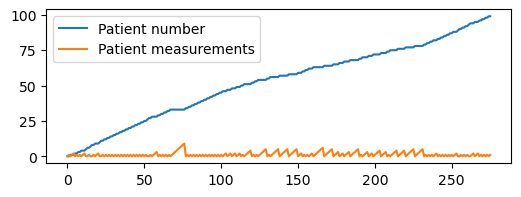

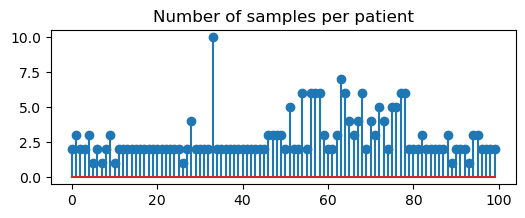

In [36]:
plt.figure(figsize=(6, 2))
plt.plot(patient_no, label="Patient number")
plt.plot(patient_sample, label="Patient measurements")
plt.legend()
plt.show()

plt.figure(figsize=(6, 2))
plt.title("Number of samples per patient")
plt.stem(streak_length(patient_no))
plt.show()

## Export of samples to `data`

In [37]:
# check dimensions
assert len(lesion_assessment) == len(lesion_loc) == Zdata.shape[0]

In [38]:
for p in range(Zdata.shape[0]):
    # print(p, int(Bx[p]), int(Case[p]), "\t", patient_no[p], patient_sample[p])
    np.savez(
        "data/sample_{0:04d}.npz".format(p),
        py_idx=p,
        patient_no=patient_no[p],  # post-processed patient numbering
        patient_sample=patient_sample[p],  # post-processed patient sample numbering
        Zdata=Zdata[p],
        Bx_Case=[int(Bx[p]), int(Case[p])],
        Case=Case[p],
        Avg_Cutpats=Avg_Cutpats[p],
        LesionLoc=lesion_loc[p],
        LesionAssessment=lesion_assessment[p],
        # if the labels are changed here -> also change in toolbox.loading load_data()!
        labels_healthy_vs_cancer=labels_healthy_vs_cancer[p],
        labels_cancer_vs_hbd=labels_cancer_vs_hbd[p],
        labels_MC=labels_MC[p],
        Sample=Sample[p],
        Category=Category[p],
    )

___